# Lab 2 — What Did the Campaign Deliver?
Name: Valentyna Tkachenko | Group: КМ-41

## Setup

In [22]:
!pip install kagglehub -q
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

for name, df in [("commercials", commercials), ("rate_card", rate_card)]:
    print(name, df.shape)

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.
commercials (167720, 9)
rate_card (81, 8)


## Task 1.1 — Size

In [23]:
brand_a = commercials[commercials["brand"] == "BRAND_A"]

print("Spots:", len(commercials))
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", len(brand_a))
brand_a["network_code"].value_counts().rename("BRAND_A spots").to_frame()   # table: BRAND_A spots by network

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,BRAND_A spots
network_code,
FNC,40
HGTV,39
FX,38
HIST,37
BRAVO,33
FOOD,33
ABC,29
CBS,22
NBC,16


## Task 1.2 — Ad load

In [24]:
import numpy as np

BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]
NETWORKS = BIG + SMALL

commercials["start_ts"] = pd.to_datetime(commercials["start_ts"])

ads = commercials.assign(hour=commercials["start_ts"].dt.floor("h"))
ad_min_per_hour = ads.groupby(["network_code", "hour"])["length_sec"].sum() / 60

load = (ad_min_per_hour.groupby("network_code")
        .agg(ad_min_per_hour="mean", hours_with_ads="size")
        .reindex(NETWORKS))
load["hours_without_ads"] = 31 * 24 - load["hours_with_ads"]
display(load.round(1))   # table: ad minutes per hour by network

print("Heaviest ad load:", load["ad_min_per_hour"].idxmax())

,ad_min_per_hour,hours_with_ads,hours_without_ads
network_code,,,
CBS,12.1,427,317
NBC,11.8,299,445
ABC,11.8,349,395
FOX,11.8,196,548
FNC,15.6,743,1
FX,12.9,621,123
BRAVO,13.4,623,121
HGTV,13.3,621,123
FOOD,13.1,620,124


Heaviest ad load: FNC


In [25]:
# Which programs fill the broadcast networks' hours without national ads?
no_ads = programs[programs["network_code"].isin(["CBS", "NBC", "ABC", "FOX"])
                  & ~programs["telecast_id"].isin(commercials["telecast_id"])]
(no_ads.groupby("program_name")["duration_min"].sum().div(60).round(1)
 .sort_values(ascending=False).rename("hours without national ads").head(5).to_frame())

,hours without national ads
program_name,
Local / Syndicated Programming,1844.7
Vice Presidential Debate (Vance vs Walz),5.2
NBC Nightly News,0.2
Law & Order,0.1
Found,0.1


**Answer:** Fox News (FNC) carries the heaviest ad load, about 15.6 ad minutes per hour, and it has national ads in 743 of the 744 hours of October. The broadcast networks run about 12 minutes per hour, but they have 317 (CBS) to 548 (FOX) clock hours with no national spot at all.

CBS, NBC, ABC and FOX are networks of affiliated local stations. The network feeds programming only in its own dayparts: morning shows, daytime, evening news, prime, late night and sports. The rest of the day belongs to the local station. The table shows this: about 1,845 hours of "Local / Syndicated Programming" across the four networks (local news and syndicated shows). The station sells those breaks to local advertisers, so they are not in a national ad log. FOX has the most empty hours because the FOX network feeds only two hours of prime a night plus sports. The vice-presidential debate (about 5 hours) also ran without ads.

## Task 1.3 — Price everything

In [26]:
SIX = pd.Timedelta(hours=6)

# 1) program name for every spot
spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")

# 2) program rows win: match on network + program name
prog_rows = rate_card[rate_card["program_name"].notna()][["network_code", "program_name", "daypart", "cost_30s_usd"]]
spots = spots.merge(prog_rows, on=["network_code", "program_name"], how="left")
spots["row_kind"] = np.where(spots["daypart"].notna(), "program", "time")

# 3) time rows: broadcast weekday + minutes since 06:00
def clock_to_min(s):
    h, m = str(s).split(":")
    return int(h) * 60 + int(m) - 360

time_rows = rate_card[rate_card["program_name"].isna()].copy()
time_rows["start_min"] = time_rows["start_time"].map(clock_to_min)
time_rows["end_min"] = time_rows["end_time"].map(clock_to_min)
time_rows = time_rows.explode("weekdays")
time_rows["weekday"] = time_rows["weekdays"].astype(int)

shifted = spots["start_ts"] - SIX
spots["bd_weekday"] = shifted.dt.weekday
spots["minute"] = shifted.dt.hour * 60 + shifted.dt.minute

todo = spots.loc[spots["row_kind"] == "time", ["ad_airing_id", "network_code", "bd_weekday", "minute"]]
m = todo.merge(time_rows[["network_code", "weekday", "start_min", "end_min", "daypart", "cost_30s_usd"]],
               left_on=["network_code", "bd_weekday"], right_on=["network_code", "weekday"])
m = m[(m["minute"] >= m["start_min"]) & (m["minute"] < m["end_min"])]
print("Each spot matched at most one time row:", m["ad_airing_id"].is_unique)
m = m.set_index("ad_airing_id")

is_time = spots["row_kind"] == "time"
spots.loc[is_time, "daypart"] = spots.loc[is_time, "ad_airing_id"].map(m["daypart"])
spots.loc[is_time, "cost_30s_usd"] = spots.loc[is_time, "ad_airing_id"].map(m["cost_30s_usd"])

# 4) cost = :30 price x length factor
spots["cost_usd"] = spots["cost_30s_usd"] * spots["length_sec"] / 30

print("Spots without a price:", int(spots["cost_usd"].isna().sum()))

Each spot matched at most one time row: True
Spots without a price: 0


In [27]:
value = spots.groupby("network_code").agg(spots=("ad_airing_id", "size"),
                                          value_usd_m=("cost_usd", "sum"))
value["program_rows_usd_m"] = spots[spots["row_kind"] == "program"].groupby("network_code")["cost_usd"].sum()
value = value.reindex(NETWORKS).fillna({"program_rows_usd_m": 0})
value["share_program_rows"] = value["program_rows_usd_m"] / value["value_usd_m"]
value[["value_usd_m", "program_rows_usd_m"]] /= 1e6
value.round({"value_usd_m": 1, "program_rows_usd_m": 1, "share_program_rows": 3})   # table: rate-card value by network (USD M) and share from program rows

,spots,value_usd_m,program_rows_usd_m,share_program_rows
network_code,,,,
CBS,12835,818.8,188.6,0.230
NBC,8772,724.3,247.6,0.342
ABC,10202,708.8,305.9,0.432
FOX,5725,696.2,581.5,0.835
FNC,28579,315.8,0.0,0.000
FX,19911,42.5,0.0,0.000
BRAVO,20743,25.3,0.0,0.000
HGTV,20417,58.1,0.0,0.000
FOOD,20213,42.1,0.0,0.000


In [28]:
print("Total rate-card value, all networks (USD M):", round(value["value_usd_m"].sum(), 1))
print("Share from program rows (sports), all networks:", round(value["program_rows_usd_m"].sum() / value["value_usd_m"].sum(), 3))

Total rate-card value, all networks (USD M): 3472.1
Share from program rows (sports), all networks: 0.381


## Task 2.1 — Delivery

In [29]:
viewings["start_ts"] = pd.to_datetime(viewings["start_ts"])
viewings["end_ts"] = pd.to_datetime(viewings["end_ts"])
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])

def broadcast_date(ts):
    """Broadcast day (06:00-05:59) of a timestamp series."""
    return (ts - SIX).dt.normalize()

# persons = R and L; monthly weight = average weight over in-tab days
pw = daily_weights[daily_weights["resp_type"].isin(["R", "L"])].copy()
age = (viewer_attributes[viewer_attributes["attr_id"] == 300]
       .drop_duplicates("respondent_id").set_index("respondent_id")["value"])
female_ids = set(viewer_attributes.loc[viewer_attributes["attr_id"] == 202, "respondent_id"])

persons = pw.groupby("respondent_id")["weight"].mean().rename("monthly_weight").reset_index()
persons["age"] = persons["respondent_id"].map(age)
persons["a18_49"] = persons["age"].between(18, 49)
persons["w18_34"] = persons["respondent_id"].isin(female_ids) & persons["age"].between(18, 34)
pw = pw.merge(persons[["respondent_id", "a18_49", "w18_34"]], on="respondent_id")

# daily universes: sum of weights of everyone in-tab that day, by audience
universe = pw.groupby("broadcast_date").agg(univ_p2=("weight", "sum"), n_intab=("weight", "size"))
universe["univ_a18_49"] = pw[pw["a18_49"]].groupby("broadcast_date")["weight"].sum()
universe["univ_w18_34"] = pw[pw["w18_34"]].groupby("broadcast_date")["weight"].sum()

print("Persons (R+L):", len(persons))
print("A18-49 share of persons:", round(persons.loc[persons.a18_49, "monthly_weight"].sum() / persons["monthly_weight"].sum(), 3))

Persons (R+L): 10210
A18-49 share of persons: 0.422


In [30]:
camp = spots[spots["brand"] == "BRAND_A"].copy()
camp["broadcast_date"] = broadcast_date(camp["start_ts"])
camp["group"] = np.where(camp["network_code"].isin(BIG), "big", "small")

pv = viewings[viewings["resp_type"].isin(["R", "L"])]
by_net = {n: (g["respondent_id"].to_numpy(), g["start_ts"].to_numpy(), g["end_ts"].to_numpy())
          for n, g in pv.groupby("network_code")}

def get_exposures(spot_table):
    """One row per (spot, person who was watching the spot's network at its start)."""
    parts = []
    for s in spot_table.itertuples():
        rid, st, en = by_net[s.network_code]
        t = np.datetime64(s.start_ts)
        hit = (st <= t) & (en > t)
        parts.append(pd.DataFrame({"ad_airing_id": s.ad_airing_id, "respondent_id": rid[hit]}))
    exp = pd.concat(parts, ignore_index=True)
    exp = exp.merge(spot_table[["ad_airing_id", "network_code", "group", "broadcast_date"]], on="ad_airing_id")
    # the person's weight on the spot's broadcast day
    exp = exp.merge(pw[["respondent_id", "broadcast_date", "weight", "a18_49", "w18_34"]],
                    on=["respondent_id", "broadcast_date"], how="left")
    return exp

exposures = get_exposures(camp)
print("Exposures (spot x person rows):", len(exposures))
print("Exposures without a weight:", int(exposures["weight"].isna().sum()))

Exposures (spot x person rows): 11289
Exposures without a weight: 0


In [31]:
def add_spot_metrics(spot_table, exp):
    """Spot-level impressions, ratings and panelist counts."""
    t = spot_table.merge(universe, left_on="broadcast_date", right_index=True, how="left")
    g = exp.groupby("ad_airing_id")
    t["imp_p2"] = t["ad_airing_id"].map(g["weight"].sum()).fillna(0)
    t["imp_a18_49"] = t["ad_airing_id"].map(exp[exp.a18_49].groupby("ad_airing_id")["weight"].sum()).fillna(0)
    t["panelists"] = t["ad_airing_id"].map(g.size()).fillna(0).astype(int)
    t["panelists_w18_34"] = t["ad_airing_id"].map(exp[exp.w18_34].groupby("ad_airing_id").size()).fillna(0).astype(int)
    t["rtg_p2"] = t["imp_p2"] / t["univ_p2"] * 100
    t["rtg_a18_49"] = t["imp_a18_49"] / t["univ_a18_49"] * 100
    return t

camp = add_spot_metrics(camp, exposures)

def reach_pct(exp, audience=None):
    """Reach = monthly weights of people who saw >= 1 spot / monthly weights of the whole audience x 100."""
    pop = persons if audience is None else persons[persons[audience]]
    seen = pop["respondent_id"].isin(exp["respondent_id"])
    return pop.loc[seen, "monthly_weight"].sum() / pop["monthly_weight"].sum() * 100

grp_p2, grp_a = camp["rtg_p2"].sum(), camp["rtg_a18_49"].sum()
reach_p2, reach_a = reach_pct(exposures), reach_pct(exposures, "a18_49")

print("P2+ impressions (M):", round(camp["imp_p2"].sum() / 1e6, 1))
print("P2+ GRPs:", round(grp_p2, 1))
print("P2+ reach (%):", round(reach_p2, 1))
print("P2+ average frequency:", round(grp_p2 / reach_p2, 1))
print("A18-49 impressions (M):", round(camp["imp_a18_49"].sum() / 1e6, 1))
print("A18-49 GRPs:", round(grp_a, 1))
print("A18-49 reach (%):", round(reach_a, 1))
print("A18-49 average frequency:", round(grp_a / reach_a, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

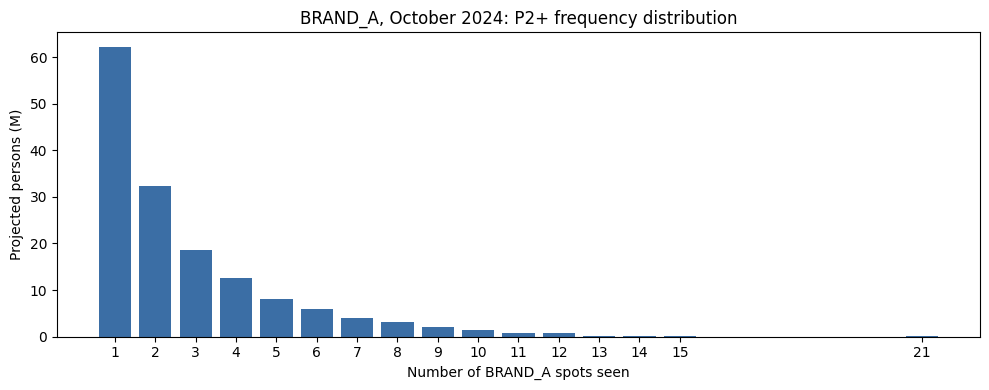

Persons reached (M): 152.3
Share of reached who saw exactly 1 spot: 0.409
Share of reached who saw 5+ spots: 0.175
Reach at 3+ exposures (%): 16.5
Max spots seen by one person: 21
Share of impressions at 5+ exposures: 0.444


In [32]:
freq = exposures.groupby("respondent_id").size().rename("spots_seen")
fd = persons.merge(freq, left_on="respondent_id", right_index=True)
dist = fd.groupby("spots_seen")["monthly_weight"].sum() / 1e6

# plot: projected persons (M) by number of spots seen
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dist.index, dist.values, color="#3b6ea5")
ax.set_xlabel("Number of BRAND_A spots seen")
ax.set_ylabel("Projected persons (M)")
ax.set_title("BRAND_A, October 2024: P2+ frequency distribution")
ax.set_xticks(dist.index)
plt.tight_layout()
plt.show()

exposures["person_freq"] = exposures["respondent_id"].map(freq)
share_5p = exposures.loc[exposures["person_freq"] >= 5, "weight"].sum() / exposures["weight"].sum()
reached = dist.sum()

print("Persons reached (M):", round(reached, 1))
print("Share of reached who saw exactly 1 spot:", round(dist.loc[1] / reached, 3))
print("Share of reached who saw 5+ spots:", round(dist[dist.index >= 5].sum() / reached, 3))
print("Reach at 3+ exposures (%):", round(dist[dist.index >= 3].sum() * 1e6 / persons["monthly_weight"].sum() * 100, 1))
print("Max spots seen by one person:", int(freq.max()))
print("Share of impressions at 5+ exposures:", round(share_5p, 3))

**Answer:** No. The average frequency of 3.0 hides a very uneven distribution. Of the 152.3M people reached, 41% saw the ad only once, and only 16.5% of all persons saw it 3 or more times. At the other end, the 17.5% of the reached who saw 5 or more spots absorbed 44.4% of all impressions, and one panelist saw 21 spots. The distribution has a long right tail: heavy viewers (people who watch Fox News, morning shows and daytime for hours every day) get the same ad again and again, while most of the audience gets one or two exposures. So "3.0" overstates what a typical viewer saw and hides the wasted impressions in the tail. It is better to report the whole distribution, or effective reach (e.g. 3+), next to the average.

## Task 2.3 — On target?

In [33]:
pop_share = persons.loc[persons.a18_49, "monthly_weight"].sum() / persons["monthly_weight"].sum()
print("A18-49 share of all persons:", round(pop_share, 3))
print("Share of impressions on A18-49:", round(camp["imp_a18_49"].sum() / camp["imp_p2"].sum(), 3))

on_target = camp.groupby("network_code").agg(
    spots=("ad_airing_id", "size"), imp_p2_m=("imp_p2", "sum"), imp_a18_49_m=("imp_a18_49", "sum"))
on_target["share_a18_49"] = on_target["imp_a18_49_m"] / on_target["imp_p2_m"]
on_target["index_vs_pop"] = on_target["share_a18_49"] / pop_share * 100
on_target["share_of_campaign_imp"] = on_target["imp_p2_m"] / on_target["imp_p2_m"].sum()
on_target[["imp_p2_m", "imp_a18_49_m"]] /= 1e6
on_target.reindex(NETWORKS).round({"imp_p2_m": 1, "imp_a18_49_m": 1, "share_a18_49": 3,
                                    "index_vs_pop": 0, "share_of_campaign_imp": 3})

A18-49 share of all persons: 0.422
Share of impressions on A18-49: 0.194


,spots,imp_p2_m,imp_a18_49_m,share_a18_49,index_vs_pop,share_of_campaign_imp
network_code,,,,,,
CBS,22,89.0,13.7,0.154,36.0,0.212
NBC,16,41.4,7.8,0.189,45.0,0.099
ABC,29,94.2,17.0,0.180,43.0,0.225
FOX,13,76.3,18.4,0.242,57.0,0.182
FNC,40,57.8,2.7,0.047,11.0,0.138
FX,38,8.5,5.6,0.651,154.0,0.020
BRAVO,33,5.1,2.8,0.554,131.0,0.012
HGTV,39,24.7,7.6,0.306,73.0,0.059
FOOD,33,9.5,3.0,0.316,75.0,0.023


**Answer:** The plan clearly under-delivered against its target. Adults 18–49 are 42.2% of all persons, but they received only 19.4% of the campaign's impressions, an index of about 46. As a result the campaign got only 60.4 A18–49 GRPs against 132.0 P2+ GRPs, and A18–49 reach was 30.5% against 43.5% for P2+.

The networks explain it. Most impressions came from the big networks, whose audiences in the dayparts bought are old. CBS (21% of impressions, index 36), ABC (22%, index 43), FOX (18%, index 57) and NBC (10%, index 45) all under-index. Fox News is the worst: it had the most spots of any network (40) and 14% of impressions, but only 4.7% of them reached A18–49 (index 11). Many broadcast spots also ran in morning shows, daytime and news, which skew old. Only FX (65% of impressions on the target, index 154) and Bravo (55%, index 131) over-deliver, but together they are just 3% of the campaign's impressions.

## Task 3.1 — Cost

In [34]:
cost = camp["cost_usd"].sum()
imp_p2, imp_a = camp["imp_p2"].sum(), camp["imp_a18_49"].sum()
cpp_p2 = cost / grp_p2

print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", round(cost / imp_p2 * 1000, 2))
print("P2+ CPP (USD):", round(cpp_p2))
print("A18-49 CPM (USD):", round(cost / imp_a * 1000, 2))
print("A18-49 CPP (USD):", round(cost / grp_a))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [35]:
bynet = camp.groupby("network_code").agg(
    spots=("ad_airing_id", "size"), cost_usd=("cost_usd", "sum"),
    imp_p2_m=("imp_p2", "sum"), imp_a18_49_m=("imp_a18_49", "sum"))
bynet["cost_share"] = bynet["cost_usd"] / bynet["cost_usd"].sum()
bynet["p2_cpm_usd"] = bynet["cost_usd"] / bynet["imp_p2_m"] * 1000
bynet["a18_49_cpm_usd"] = bynet["cost_usd"] / bynet["imp_a18_49_m"] * 1000
bynet[["imp_p2_m", "imp_a18_49_m"]] /= 1e6
bynet = bynet.reindex(NETWORKS)
# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network
bynet.round({"imp_p2_m": 1, "imp_a18_49_m": 1, "cost_share": 3,
             "p2_cpm_usd": 2, "a18_49_cpm_usd": 2}).astype({"cost_usd": int})

,spots,cost_usd,imp_p2_m,imp_a18_49_m,cost_share,p2_cpm_usd,a18_49_cpm_usd
network_code,,,,,,,
CBS,22,1488700,89.0,13.7,0.201,16.73,108.72
NBC,16,796800,41.4,7.8,0.107,19.23,101.72
ABC,29,1625700,94.2,17.0,0.219,17.26,95.69
FOX,13,2434700,76.3,18.4,0.328,31.93,132.03
FNC,40,526300,57.8,2.7,0.071,9.11,193.70
FX,38,92200,8.5,5.6,0.012,10.82,16.61
BRAVO,33,49610,5.1,2.8,0.007,9.76,17.61
HGTV,39,230000,24.7,7.6,0.031,9.33,30.45
FOOD,33,96620,9.5,3.0,0.013,10.19,32.29


In [36]:
(camp.groupby(["network_code", "daypart"])
 .agg(spots=("ad_airing_id", "size"), cost_usd=("cost_usd", "sum"), imp_a18_49_m=("imp_a18_49", "sum"))
 .assign(a18_49_cpm_usd=lambda t: (t.cost_usd / t.imp_a18_49_m * 1000).round(2),
         imp_a18_49_m=lambda t: (t.imp_a18_49_m / 1e6).round(1),
         cost_usd=lambda t: t.cost_usd.round().astype(int))
 .sort_values("cost_usd", ascending=False).head(10))

spots  cost_usd  imp_a18_49_m  \
network_code daypart                                                        
FOX          MLB Postseason & World Series      4   1320800           9.2   
ABC          College Football                   7    777700           9.4   
FOX          College Football                   4    547200           5.2   
CBS          NFL on CBS                         2    445200           2.8   
             Prime                              2    357600           4.8   
ABC          Weekend Prime                      2    347600           2.0   
FOX          NFL on FOX                         2    347200           1.5   
NBC          Prime                              2    346800           0.9   
             Today                             11    320100           4.4   
CBS          Sunday Prime                       1    202400           1.6   

                                            a18_49_cpm_usd  
network_code daypart                                        
FOX          MLB Postseason & World Series          142.90  
ABC          College Football                        82.53  
FOX          College Football                       105.45  
CBS          NFL on CBS                             161.49  
             Prime                                   73.95  
ABC          Weekend Prime                          172.93  
FOX          NFL on FOX                             231.99  
NBC          Prime                                  385.94  
             Today                                   72.98  
CBS          Sunday Prime                           127.39

**Answer:** The money went almost entirely to the big networks: 92.6% of the USD 7.42M budget. FOX alone took 33% (USD 2.43M for only 13 spots). Most of that was four MLB Postseason / World Series spots at USD 330,200 each, plus NFL and college football. ABC (22%), CBS (20%) and NBC (11%) follow, mostly with sports and prime. The five small networks got only 7.4% of the budget for 180 of the 300 spots.

For the target, the small networks are by far the cheapest. FX (USD 16.61 per thousand A18–49 impressions) and Bravo (USD 17.61) cost about one sixth of the broadcast networks (USD 96–132). HGTV, History and Food Network cost about USD 30–32. Fox News is the most expensive way to reach A18–49 (USD 193.70), even though it has the lowest P2+ CPM of the big networks (USD 9.11): its audience is cheap but old. Sports and prime on broadcast give scale, with millions of A18–49 per spot, but at a premium price.

## Task 3.3 — Guarantee

In [37]:
GUARANTEE = 150
owed = max(0.0, GUARANTEE - grp_p2)

print("Guarantee met:", bool(grp_p2 >= GUARANTEE))            # True / False
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cpp_p2))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [38]:
r_big = reach_pct(exposures[exposures["group"] == "big"])
r_small = reach_pct(exposures[exposures["group"] == "small"])
r_all = reach_pct(exposures)
overlap = r_big + r_small - r_all
indep = r_big * r_small / 100
cost_big = camp.loc[camp["group"] == "big", "cost_usd"].sum()
cost_small = camp.loc[camp["group"] == "small", "cost_usd"].sum()
added = r_all - r_big

print("Reach, big networks (%):", round(r_big, 1))
print("Reach, small networks (%):", round(r_small, 1))
print("Reach, whole campaign (%):", round(r_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(indep, 1))
print("Reach added by small networks (points):", round(added, 1))
print("Cost per added reach point, small (USD):", round(cost_small / added))
print("Cost per reach point, big (USD):", round(cost_big / r_big))
print()
print("Share of small-network reach also reached by big networks:", round(overlap / r_small, 3))
print("Small-network share of budget:", round(cost_small / cost, 3))
print("Small-network share of P2+ GRPs:", round(camp.loc[camp.group == "small", "rtg_p2"].sum() / grp_p2, 3))
print("Small-network share of A18-49 impressions:", round(camp.loc[camp.group == "small", "imp_a18_49"].sum() / imp_a, 3))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456

Share of small-network reach also reached by big networks: 0.702
Small-network share of budget: 0.074
Small-network share of P2+ GRPs: 0.143
Small-network share of A18-49 impressions: 0.264


**Answer:** Reach does not add because the same people can see spots on both groups of networks. The big networks alone reach 39.8% of persons and the small networks 12.4%. The sum is 52.2%, but the campaign reaches only 43.5%: the 8.7% who saw spots in both groups are counted twice in the sum.

If the two audiences were independent, the overlap would be 39.8% × 12.4% = 4.9%. The real overlap, 8.7%, is about 1.8 times as much. Of the people reached on the small networks, 70% were also reached by the big ones, while the big networks reach only 40% of the population overall. So small-network viewers are much more likely than average to have seen the big-network spots too. A likely reason is that people who watch cable lifestyle channels tend to be heavy TV viewers who also spend many hours on broadcast and Fox News. Heavy viewers are the most likely to catch any spot anywhere, so the audiences duplicate.

The small networks added only 3.7 points of reach. At USD 548k that is about USD 148.7k per added point, a bit cheaper than the USD 172.5k per reach point on the big networks. In addition, for 7.4% of the budget the small networks delivered 14.3% of the P2+ GRPs and 26.4% of all A18–49 impressions. So the small-network money was well spent, especially for the target. The extra reach was limited by duplication, and the small-network numbers rest on very few panelists (Task 5).

## Task 5 — How sure are we?

In [39]:
p = camp["rtg_p2"] / 100
camp["se_p2"] = np.sqrt(p * (1 - p) / camp["n_intab"]) * 100
camp["rel_se"] = (camp["se_p2"] / camp["rtg_p2"]).where(camp["rtg_p2"] > 0)   # undefined for a zero rating

# table: median panelists per spot and median relative SE, by network
sure = camp.groupby("network_code").agg(
    spots=("ad_airing_id", "size"),
    median_panelists=("panelists", "median"),
    spots_no_panelist=("panelists", lambda s: int((s == 0).sum())),
    median_rating_p2=("rtg_p2", "median"),
    median_rel_se=("rel_se", "median"),
    w18_34_zero_cells=("panelists_w18_34", lambda s: int((s == 0).sum())),
).reindex(NETWORKS)
display(sure.round({"median_panelists": 1, "median_rating_p2": 2, "median_rel_se": 3}))

zero = camp["panelists"] == 0
print("Spots seen by no panelist:", int(zero.sum()))
print("Rating of those spots:", round(camp.loc[zero, "rtg_p2"].max(), 1))
print("Median relative SE, big networks:", round(camp.loc[camp.group == "big", "rel_se"].median(), 3))
print("Median relative SE, small networks:", round(camp.loc[camp.group == "small", "rel_se"].median(), 3))
print("W18-34 zero-cell spots:", int((camp["panelists_w18_34"] == 0).sum()))
print()
print("Median panelists per spot, big / small:",
      camp.loc[camp.group == "big", "panelists"].median(), "/", camp.loc[camp.group == "small", "panelists"].median())
print("Median in-tab persons per day:", int(universe["n_intab"].median()))
print("W18-34 persons in-tab per day (median):", int(pw[pw.w18_34].groupby("broadcast_date").size().median()))

,spots,median_panelists,spots_no_panelist,median_rating_p2,median_rel_se,w18_34_zero_cells
network_code,,,,,,
CBS,22,69.0,0,0.84,0.113,10
NBC,16,68.5,0,0.81,0.115,5
ABC,29,57.0,0,0.71,0.123,8
FOX,13,145.0,0,1.64,0.080,0
FNC,40,31.0,0,0.40,0.164,31
FX,38,5.5,4,0.05,0.423,16
BRAVO,33,3.0,3,0.03,0.540,20
HGTV,39,11.0,0,0.12,0.301,24
FOOD,33,5.0,2,0.06,0.423,26


Spots seen by no panelist: 10
Rating of those spots: 0.0
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171

Median panelists per spot, big / small: 57.5 / 5.0
Median in-tab persons per day: 9264
W18-34 persons in-tab per day (median): 953


**Answer:** The 10 spots that no panelist saw are all on small networks (FX 4, Bravo 3, Food 2, History 1), and their rating is exactly 0.0. That does not mean nobody saw them. It means the audience was too small for the panel to detect. With about 9,300 persons in-tab per day, each panelist stands for about 34,000 people. A spot with a true rating of 0.02 (about 60,000 viewers) would on average be seen by about 1.9 panelists, and would still have about a 15% chance of being seen by none. On small networks the median spot is seen by only 5 panelists (Bravo: 3), against 57.5 on big networks (FOX: 145). The median relative standard error is 42% on small networks against 12% on big ones, and real errors are larger still, because a weighted panel behaves like a smaller sample. So spot-level ratings on small networks are mostly sampling noise. Only aggregates over many spots (network totals, monthly GRPs) can be used.

For W18–34, 171 of the 300 spots (57%) are zero-cells: no woman aged 18–34 in the panel saw them. Only about 950 such women are in-tab per day, so a single panelist moves a spot's W18–34 rating by about 0.1 points. I would tell the client that we cannot give a reliable W18–34 rating spot by spot: the numbers would be mostly zeros with a few jumps caused by single panelists, and a zero means "below what the panel can measure", not "nobody watched". We can report W18–34 for the campaign as a whole (total GRPs and reach) with a confidence interval, or per network for the month. If spot-level detail is really needed, a broader demo such as W18–49 or A18–49, or larger data (set-top-box / smart-TV data combined with the panel), would be the honest alternative.

## Bonus

In [40]:
# Sweep per network: +weight at session start, -weight at session end;
# audience at time t = cumulative sum of all events at or before t (start <= t < end).
pv18 = pv.merge(persons.loc[persons.a18_49, ["respondent_id"]], on="respondent_id")
spots["broadcast_date"] = broadcast_date(spots["start_ts"])
spots["aud_a18_49"] = 0.0
for net, g in pv18.groupby("network_code"):
    t = np.concatenate([g["start_ts"].to_numpy(), g["end_ts"].to_numpy()])
    w = np.concatenate([g["weight"].to_numpy(), -g["weight"].to_numpy()]).astype(float)
    order = np.argsort(t, kind="stable")
    t, cw = t[order], np.cumsum(w[order])
    idx = spots.index[spots["network_code"] == net]
    pos = np.searchsorted(t, spots.loc[idx, "start_ts"].to_numpy(), side="right") - 1
    spots.loc[idx, "aud_a18_49"] = np.where(pos >= 0, cw[np.clip(pos, 0, None)], 0)

inv = spots[spots["length_sec"] == 30].groupby(["network_code", "daypart"]).agg(
    spots_in_month=("ad_airing_id", "size"),
    price_30s=("cost_30s_usd", "first"),
    avg_imp_a18_49_k=("aud_a18_49", "mean"))
inv["a18_49_cpm_usd"] = inv["price_30s"] / inv["avg_imp_a18_49_k"] * 1000
inv["avg_imp_a18_49_k"] /= 1000
print("Best-value A18-49 inventory (at least 100 :30s in the month and >= 300k A18-49 per spot):")
inv[(inv.spots_in_month >= 100) & (inv.avg_imp_a18_49_k >= 300)].sort_values("a18_49_cpm_usd").head(8).round(2)

Best-value A18-49 inventory (at least 100 :30s in the month and >= 300k A18-49 per spot):


,,spots_in_month,price_30s,avg_imp_a18_49_k,a18_49_cpm_usd
network_code,daypart,,,,
FOX,Run of Schedule,615,16300.0,1026.55,15.88
FX,Prime,2312,8000.0,432.36,18.50
HGTV,Prime,1829,12900.0,351.77,36.67
ABC,Weekend Day,280,20400.0,473.25,43.11
NBC,Weekend Day,276,25000.0,564.84,44.26
CBS,Weekend Day,619,26500.0,495.88,53.44
NBC,Nightly News & Early Fringe,208,36900.0,659.12,55.98
ABC,World News & Early Fringe,203,28500.0,475.09,59.99


In [41]:
camp_inv = camp.merge(inv[["a18_49_cpm_usd"]].rename(columns={"a18_49_cpm_usd": "daypart_a18_49_cpm"}),
                      left_on=["network_code", "daypart"], right_index=True, how="left")
drop = camp_inv.sort_values("daypart_a18_49_cpm", ascending=False).head(20)
budget = drop["cost_usd"].sum()
print("Spots dropped:", len(drop), "| budget freed (USD):", round(budget),
      "| their A18-49 impressions (M):", round(drop["imp_a18_49"].sum() / 1e6, 2),
      "| their A18-49 CPM (USD):", round(budget / drop["imp_a18_49"].sum() * 1000, 2))
display(drop.groupby(["network_code", "daypart"]).agg(spots=("ad_airing_id", "size"), cost_usd=("cost_usd", "sum"),
                                                      daypart_a18_49_cpm=("daypart_a18_49_cpm", "first")).round(2))

# buy FX Prime :30s with the same money, spread evenly over the campaign weeks
fx_prime = spots[(spots["network_code"] == "FX") & (spots["daypart"] == "Prime") & (spots["length_sec"] == 30)
                 & (spots["brand"] != "BRAND_A")
                 & spots["start_ts"].between(camp["start_ts"].min(), camp["start_ts"].max())]
fx_prime = fx_prime.sort_values("start_ts").drop_duplicates("telecast_id")
n_new = int(budget // 8000)
pick = fx_prime.iloc[np.linspace(0, len(fx_prime) - 1, n_new).round().astype(int)].copy()
pick["group"] = "small"
print("FX Prime spots bought:", n_new, "| cost (USD):", round(pick["cost_usd"].sum()))

cols = ["ad_airing_id", "network_code", "start_ts", "daypart", "cost_usd", "group", "broadcast_date"]
new_camp = pd.concat([camp.loc[~camp["ad_airing_id"].isin(drop["ad_airing_id"]), cols], pick[cols]], ignore_index=True)
new_exp = get_exposures(new_camp)
new_camp = add_spot_metrics(new_camp, new_exp)

def summary(t, e):
    return pd.Series({
        "spots": len(t), "cost_usd": t["cost_usd"].sum(),
        "a18_49_imp_m": t["imp_a18_49"].sum() / 1e6, "a18_49_grps": t["rtg_a18_49"].sum(),
        "a18_49_reach_pct": reach_pct(e, "a18_49"),
        "a18_49_cpm_usd": t["cost_usd"].sum() / t["imp_a18_49"].sum() * 1000,
        "p2_grps": t["rtg_p2"].sum(), "p2_reach_pct": reach_pct(e)})

compare = pd.DataFrame({"as bought": summary(camp, exposures), "proposal": summary(new_camp, new_exp)})
compare["change"] = compare["proposal"] - compare["as bought"]
compare.round(2)

Spots dropped: 20 | budget freed (USD): 440800 | their A18-49 impressions (M): 1.49 | their A18-49 CPM (USD): 296.82


spots  cost_usd  daypart_a18_49_cpm
network_code daypart                                           
CBS          Daytime            4  118000.0              257.64
FNC          Daytime News       9  101700.0              294.04
             Early Evening      3   61500.0              332.94
             Prime Opinion      4  159600.0              263.76

FX Prime spots bought: 55 | cost (USD): 440000


,as bought,proposal,change
spots,300.00,335.00,35.00
cost_usd,7420270.00,7419470.00,-800.00
a18_49_imp_m,81.07,99.74,18.67
a18_49_grps,60.41,74.32,13.91
a18_49_reach_pct,30.47,33.65,3.19
a18_49_cpm_usd,91.53,74.39,-17.14
p2_grps,131.98,129.62,-2.36
p2_reach_pct,43.53,44.51,0.97


**Answer:** I would drop the 20 BRAND_A spots in the four network-dayparts with the worst A18–49 CPM across the whole October log: Fox News Early Evening (USD 333), Daytime News (USD 294) and Prime Opinion (USD 264), and CBS Daytime (USD 258). Together they cost USD 440,800 but delivered only 1.49M A18–49 impressions (CPM USD 297). The same money buys 55 FX Prime :30s at USD 8,000 each, spread over the campaign weeks; across the log, FX Prime averages 432k A18–49 per spot at a CPM of USD 18.50. Recomputed with the same exposure rules on real FX Prime spots from the log, at the same budget A18–49 impressions rise from 81.1M to 99.7M (+23%), the A18–49 CPM falls from USD 91.53 to USD 74.39, and A18–49 reach rises from 30.5% to 33.6%. The trade-off is 2.4 fewer P2+ GRPs (132.0 → 129.6), which slightly widens the guarantee shortfall, and the FX estimates rest on few panelists per spot, although spreading the buy over 55 spots averages much of that noise out.